# DX799 O1 - Week 6 Jupyter Notebook: Decision Trees and Random Forests
## Digital Customer Journey and E-Commerce Retention Analytics

**Student:** Javed Aamer

### Goal of this notebook

Week 6 focuses on two related ideas:

- a **decision tree** can create easy-to-follow rules, but can overfit when it grows too deep;
- a **random forest** reduces that instability by averaging many trees built from bootstrap samples and random feature subsets.

I use all four project datasets for breadth, but I do not repeat the full Week 6 workflow mechanically four times.

- **Behavior, Churn, Products, and Reviews** are used for a fair tree-versus-forest comparison.
- **Churn** is treated in depth because it is the most important retention-risk problem in the project and shows the overfitting/generalization tradeoff clearly.

The notebook emphasizes entropy, information gain, tree depth, minimum leaf size, bootstrap aggregation, feature randomization, forest size, feature importance, overfitting, and held-out evaluation.

## Concepts covered

This notebook directly applies the Week 6 concepts:

- **Decision trees**
- **Entropy**
- **Information gain**
- **Tree depth**
- **Minimum samples per split**
- **Minimum samples per leaf**
- **Overfitting in decision trees**
- **Random forests**
- **Bootstrap aggregation**
- **Feature randomization**
- **Random-forest feature importance**
- **Permutation importance as a second interpretation check**
- **Classification metrics for imbalanced outcomes**
- **Cross-validation and hyperparameter tuning**

Tree models do not require standardized numeric inputs because their decisions are based on thresholds rather than distances.

## 1. Questions I wanted to answer

1. How much does a single decision tree overfit on each project dataset?
2. Does a random forest improve held-out PR-AUC and reduce instability?
3. Are there datasets where the forest adds only a small benefit?
4. Which churn characteristics appear near the top of a decision tree?
5. How does tree depth affect training and validation performance?
6. What does information gain look like at the actual root split?
7. How much does feature randomization matter?
8. How many trees are enough before validation performance stabilizes?
9. Which predictors are most important to the fitted churn forest?
10. Which final model gives the stronger balance between predictive performance and interpretability?

In [1]:
# Imports and reproducibility
from pathlib import Path
import json
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit,
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text,
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)

RANDOM_STATE = 42

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
# Load all four cleaned project datasets
candidate_dirs = [
    Path("data"),
    Path("../data"),
    Path("data_pkg"),
    Path("../data_pkg"),
    Path("/mnt/data/dx799_rebuild/data/cleaned_week2_output"),
]

DATA_DIR = next(
    (p for p in candidate_dirs if (p / "churn_clean.csv").exists()),
    None,
)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find behavior_clean.csv, churn_clean.csv, products_clean.csv, and reviews_clean.csv."
    )

behavior = pd.read_csv(DATA_DIR / "behavior_clean.csv", low_memory=False)
churn = pd.read_csv(DATA_DIR / "churn_clean.csv", low_memory=False)
products = pd.read_csv(DATA_DIR / "products_clean.csv", low_memory=False)
reviews = pd.read_csv(DATA_DIR / "reviews_clean.csv", low_memory=False)

project_roles = pd.DataFrame({
    "Dataset": ["Behavior", "Churn", "Products", "Reviews"],
    "Rows": [len(behavior), len(churn), len(products), len(reviews)],
    "Grain": ["order/activity", "customer", "product", "review"],
    "Decision role": [
        "browse and conversion behavior",
        "retention risk",
        "catalog demand",
        "post-purchase experience",
    ],
})

print(f"Loaded data from: {DATA_DIR}")
display(project_roles)

print(
    "Join rule: Products and Reviews share ASIN/productASIN. "
    "Behavior and Churn do not have a verified common customer key, "
    "so they remain at their own valid grains."
)

Loaded data from: /mnt/data/dx799_rebuild/data/cleaned_week2_output


,Dataset,Rows,Grain,Decision role
0,Behavior,51289,order/activity,browse and conversion behavior
1,Churn,5630,customer,retention risk
2,Products,728,product,catalog demand
3,Reviews,6327,review,post-purchase experience


Join rule: Products and Reviews share ASIN/productASIN. Behavior and Churn do not have a verified common customer key, so they remain at their own valid grains.


## 2. Modeling setup

### Project-wide classification outcomes

The Week 6 breadth comparison keeps the same binary outcomes used in the Week 4 and Week 5 notebooks:

- Behavior: `Add to Cart`
- Churn: `Churn`
- Products: high recent demand
- Reviews: high sentiment

### Churn depth model

The detailed Week 6 analysis uses `Churn` (`0` = stayed, `1` = churned).

Numeric predictors:

- `Tenure`
- `CityTier`
- `WarehouseToHome`
- `HourSpendOnApp`
- `NumberOfDeviceRegistered`
- `SatisfactionScore`
- `NumberOfAddress`
- `Complain`
- `OrderAmountHikeFromlastYear`
- `CouponUsed`
- `OrderCount`
- `DaySinceLastOrder`
- `CashbackAmount`

Categorical predictors:

- `PreferredLoginDevice`
- `PreferredPaymentMode`
- `PreferedOrderCat`

`CustomerID` is excluded because it is an identifier. `Gender` and `MaritalStatus` are also left out of the Churn depth model.

Tree-based models do not require feature scaling. Numeric variables remain in their original units while categorical variables are one-hot encoded.

In [3]:
target = "Churn"

numeric_features = [
    "Tenure",
    "CityTier",
    "WarehouseToHome",
    "HourSpendOnApp",
    "NumberOfDeviceRegistered",
    "SatisfactionScore",
    "NumberOfAddress",
    "Complain",
    "OrderAmountHikeFromlastYear",
    "CouponUsed",
    "OrderCount",
    "DaySinceLastOrder",
    "CashbackAmount",
]

categorical_features = [
    "PreferredLoginDevice",
    "PreferredPaymentMode",
    "PreferedOrderCat",
]

model_features = numeric_features + categorical_features

audit = pd.DataFrame({
    "dtype": churn[model_features + [target]].dtypes.astype(str),
    "missing": churn[model_features + [target]].isna().sum(),
    "unique": churn[model_features + [target]].nunique(dropna=False),
})
display(audit)

,dtype,missing,unique
Tenure,float64,0,36
CityTier,int64,0,3
WarehouseToHome,float64,0,34
HourSpendOnApp,float64,0,6
NumberOfDeviceRegistered,int64,0,6
SatisfactionScore,int64,0,5
NumberOfAddress,int64,0,15
Complain,int64,0,2
OrderAmountHikeFromlastYear,float64,0,16
CouponUsed,float64,0,17


## 3. Class balance

Most customers in the dataset did not churn.

Because of that imbalance, I do not judge the models using accuracy alone. I also report:

- **ROC-AUC**
- **PR-AUC**
- **balanced accuracy**
- **precision**
- **recall**
- **F1**

This gives a more complete view of how well the models identify the minority churn class.

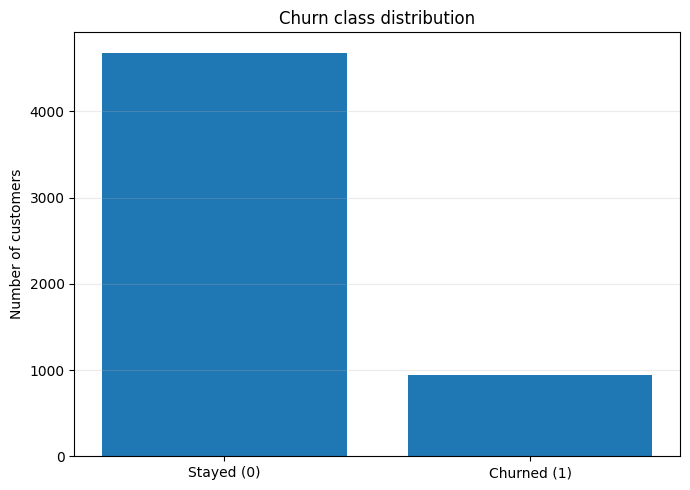

Churn rate: 16.84%


In [4]:
class_counts = churn[target].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(["Stayed (0)", "Churned (1)"], class_counts.values)
ax.set_ylabel("Number of customers")
ax.set_title("Churn class distribution")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Churn rate: {churn[target].mean():.2%}")

## 4. Project-wide classification setup

The four datasets use the same binary definitions carried forward from Weeks 4 and 5.

For Products and Reviews, the binary outcomes are project-specific operational definitions:

- **High demand:** at least 300 recent purchases.
- **High sentiment:** sentiment score above 0.30.

Behavior is split by `Customer ID` and Reviews by `productASIN` so repeated entities do not leak across train and test partitions. Churn and Products use target-stratified row splits.

The Behavior table is large, so it is capped only **after** the customer-grouped split for computational practicality.

In [5]:
# Parse product/review fields used by the project-wide Week 6 comparison.

products["rating_stars_num"] = pd.to_numeric(
    products["rating_stars"].astype(str).str.extract(r"([0-9.]+)")[0],
    errors="coerce",
)

products["rating_count_num"] = pd.to_numeric(
    products["rating_count"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"([0-9]+)")[0],
    errors="coerce",
)

def parse_recent_purchases(value):
    match = re.search(r"([\d,.]+)\s*([Kk]?)", str(value))
    if not match:
        return np.nan

    number = float(match.group(1).replace(",", ""))
    return number * 1000 if match.group(2) else number

products["recent_purchases_num"] = products["recent_purchases"].map(parse_recent_purchases)

products["list_price_num"] = pd.to_numeric(
    products["list_price"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"\$([0-9.]+)")[0],
    errors="coerce",
)

products["discount_pct"] = np.where(
    products["list_price_num"] > 0,
    (products["list_price_num"] - products["price_value"])
    / products["list_price_num"],
    0,
)

products["main_rank"] = pd.to_numeric(
    products["best_sellers_rank"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"#([0-9]+)")[0],
    errors="coerce",
)

products["in_stock"] = (
    products["availability"]
    .astype(str)
    .str.lower()
    .str.contains("in stock")
    .astype(int)
)

products["description_len"] = products["product_description"].astype(str).str.len()
products["review_summary_len"] = products["customer_review_summary"].astype(str).str.len()
products["high_demand"] = (
    products["recent_purchases_num"] >= 300
).astype(int)

reviews["review_len"] = (
    reviews["cleaned_review_text"].astype(str).str.split().str.len()
)
reviews["verified_int"] = reviews["verifiedPurchase"].astype(int)
reviews["high_sentiment"] = (
    reviews["sentiment_score"] > 0.30
).astype(int)

CLS_TASKS = {
    "Behavior": {
        "df": behavior,
        "target": "Add to Cart",
        "group": "Customer ID",
        "numeric": [
            "Browsing Time (min)",
            "Sales",
            "Quantity",
            "Discount",
            "Age",
        ],
        "categorical": [
            "Segment",
            "Ship Mode",
            "Product Category",
            "Order Priority",
            "Like",
            "Share",
        ],
    },
    "Churn": {
        "df": churn,
        "target": "Churn",
        "group": None,
        "numeric": [
            "Tenure",
            "CityTier",
            "WarehouseToHome",
            "HourSpendOnApp",
            "NumberOfDeviceRegistered",
            "SatisfactionScore",
            "NumberOfAddress",
            "Complain",
            "OrderAmountHikeFromlastYear",
            "CouponUsed",
            "OrderCount",
            "DaySinceLastOrder",
            "CashbackAmount",
        ],
        "categorical": [
            "PreferredLoginDevice",
            "PreferredPaymentMode",
            "PreferedOrderCat",
        ],
    },
    "Products": {
        "df": products,
        "target": "high_demand",
        "group": None,
        "numeric": [
            "price_value",
            "rating_stars_num",
            "rating_count_num",
            "discount_pct",
            "main_rank",
            "rank_1",
            "description_len",
            "review_summary_len",
        ],
        "categorical": ["in_stock"],
    },
    "Reviews": {
        "df": reviews,
        "target": "high_sentiment",
        "group": "productASIN",
        "numeric": [
            "rating",
            "helpfulVoteCount",
            "reviewPosition",
            "review_len",
            "verified_int",
        ],
        "categorical": [],
    },
}

,Dataset,Positive class,Negative class,Positive prevalence
0,Behavior,34196,17093,0.6667
1,Churn,948,4682,0.1684
2,Products,333,395,0.4574
3,Reviews,3157,3170,0.4990


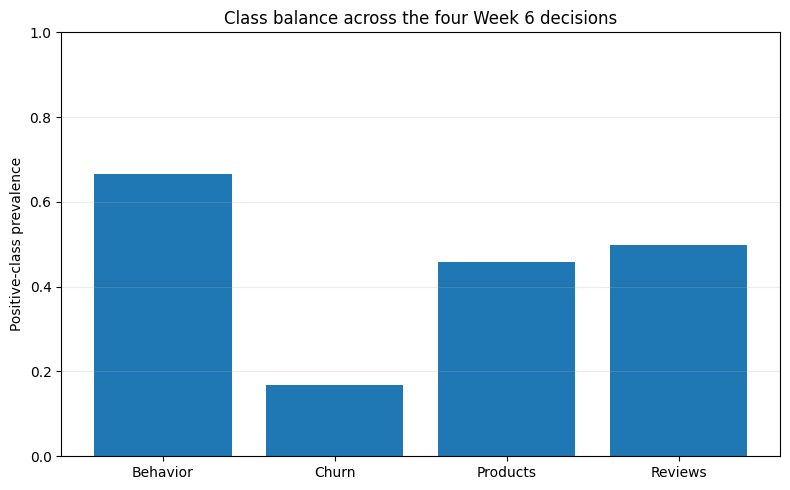

In [6]:
# Project-wide class balance

balance_rows = []

for dataset_name, task in CLS_TASKS.items():
    y = task["df"][task["target"]].astype(int)

    balance_rows.append({
        "Dataset": dataset_name,
        "Positive class": int((y == 1).sum()),
        "Negative class": int((y == 0).sum()),
        "Positive prevalence": y.mean(),
    })

project_class_balance = pd.DataFrame(balance_rows)
display(project_class_balance.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    project_class_balance["Dataset"],
    project_class_balance["Positive prevalence"],
)
ax.set_ylim(0, 1)
ax.set_ylabel("Positive-class prevalence")
ax.set_title("Class balance across the four Week 6 decisions")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Breadth: one tree versus a random forest

For breadth, I use a compact validation search on every dataset.

The purpose is not to perform an expensive exhaustive grid four times. It is to answer the Week 6 comparison consistently across the customer journey.

I tune:

- tree depth and minimum leaf size for the single tree
- depth, minimum leaf size, and feature randomization for the forest

The tuning metric is **validation PR-AUC** because the positive-class prevalence differs substantially across the four tasks.

After settings are selected, **both models are refit on training + validation data** before test evaluation. This makes the tree-versus-forest comparison fair.

In [7]:
def split_project_three(df, target, group_col=None):
    index = np.arange(len(df))

    if group_col is not None:
        groups = df[group_col].astype(str).values

        first = GroupShuffleSplit(
            n_splits=1,
            test_size=0.20,
            random_state=RANDOM_STATE,
        )
        train_validation, test = next(
            first.split(index, groups=groups)
        )

        second = GroupShuffleSplit(
            n_splits=1,
            test_size=0.25,
            random_state=RANDOM_STATE + 1,
        )
        train_relative, validation_relative = next(
            second.split(
                train_validation,
                groups=groups[train_validation],
            )
        )

        train = train_validation[train_relative]
        validation = train_validation[validation_relative]

    else:
        y = df[target].astype(int).values

        train_validation, test = train_test_split(
            index,
            test_size=0.20,
            random_state=RANDOM_STATE,
            stratify=y,
        )

        train, validation = train_test_split(
            train_validation,
            test_size=0.25,
            random_state=RANDOM_STATE + 1,
            stratify=y[train_validation],
        )

    return train, validation, test


def cap_project_indices(index, y, n_rows, seed):
    if len(index) <= n_rows:
        return index

    keep, _ = train_test_split(
        index,
        train_size=n_rows,
        random_state=seed,
        stratify=y[index],
    )

    return np.array(keep)


def make_project_preprocessor(task):
    transformers = [
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
            ]),
            task["numeric"],
        ),
    ]

    if task["categorical"]:
        transformers.append(
            (
                "categorical",
                Pipeline([
                    (
                        "imputer",
                        SimpleImputer(strategy="most_frequent"),
                    ),
                    (
                        "onehot",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            drop="first",
                        ),
                    ),
                ]),
                task["categorical"],
            )
        )

    return ColumnTransformer(transformers)


def project_metrics(y_true, probability, prediction):
    return {
        "ROC_AUC": roc_auc_score(y_true, probability),
        "PR_AUC": average_precision_score(y_true, probability),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, prediction),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
    }

In [8]:
tree_candidates = [
    {"max_depth": 3, "min_samples_leaf": 10},
    {"max_depth": 5, "min_samples_leaf": 10},
    {"max_depth": 8, "min_samples_leaf": 5},
    {"max_depth": 12, "min_samples_leaf": 2},
    {"max_depth": None, "min_samples_leaf": 2},
]

forest_candidates = [
    {
        "n_estimators": 60,
        "max_depth": 5,
        "min_samples_leaf": 20,
        "max_features": "sqrt",
    },
    {
        "n_estimators": 60,
        "max_depth": 10,
        "min_samples_leaf": 10,
        "max_features": "sqrt",
    },
    {
        "n_estimators": 60,
        "max_depth": None,
        "min_samples_leaf": 20,
        "max_features": "sqrt",
    },
]

breadth_rows = []
breadth_importances = {}
breadth_best_settings = {}

for dataset_name, task in CLS_TASKS.items():
    df = task["df"]
    y = df[task["target"]].astype(int).values

    train_idx, validation_idx, test_idx = split_project_three(
        df,
        task["target"],
        task["group"],
    )

    if dataset_name == "Behavior":
        train_idx = cap_project_indices(
            train_idx, y, 8000, 42
        )
        validation_idx = cap_project_indices(
            validation_idx, y, 2000, 43
        )
        test_idx = cap_project_indices(
            test_idx, y, 3000, 44
        )

    preprocessor = make_project_preprocessor(task)

    X_train = preprocessor.fit_transform(
        df.iloc[train_idx]
    )
    X_validation = preprocessor.transform(
        df.iloc[validation_idx]
    )

    class_weight = (
        "balanced"
        if dataset_name == "Churn"
        else None
    )

    # Select tree settings on validation PR-AUC.
    tree_scores = []

    for settings in tree_candidates:
        candidate = DecisionTreeClassifier(
            criterion="entropy",
            random_state=RANDOM_STATE,
            class_weight=class_weight,
            **settings,
        )

        candidate.fit(
            X_train,
            y[train_idx],
        )

        probability = candidate.predict_proba(
            X_validation
        )[:, 1]

        tree_scores.append(
            (
                average_precision_score(
                    y[validation_idx],
                    probability,
                ),
                settings,
            )
        )

    best_tree_settings = max(
        tree_scores,
        key=lambda row: row[0],
    )[1]

    # Select forest settings on validation PR-AUC.
    forest_scores = []

    for settings in forest_candidates:
        candidate = RandomForestClassifier(
            criterion="entropy",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            class_weight=class_weight,
            **settings,
        )

        candidate.fit(
            X_train,
            y[train_idx],
        )

        probability = candidate.predict_proba(
            X_validation
        )[:, 1]

        forest_scores.append(
            (
                average_precision_score(
                    y[validation_idx],
                    probability,
                ),
                settings,
            )
        )

    best_forest_settings = max(
        forest_scores,
        key=lambda row: row[0],
    )[1]

    breadth_best_settings[dataset_name] = {
        "tree": best_tree_settings,
        "forest": best_forest_settings,
    }

    # Fair final refit on train + validation for both models.
    development_idx = np.concatenate(
        [train_idx, validation_idx]
    )

    final_preprocessor = make_project_preprocessor(task)

    X_development = final_preprocessor.fit_transform(
        df.iloc[development_idx]
    )
    X_test = final_preprocessor.transform(
        df.iloc[test_idx]
    )

    feature_names = (
        final_preprocessor
        .get_feature_names_out()
    )

    tree = DecisionTreeClassifier(
        criterion="entropy",
        random_state=RANDOM_STATE,
        class_weight=class_weight,
        **best_tree_settings,
    )

    tree.fit(
        X_development,
        y[development_idx],
    )

    tree_train_probability = tree.predict_proba(
        X_development
    )[:, 1]

    tree_test_probability = tree.predict_proba(
        X_test
    )[:, 1]

    tree_test_prediction = tree.predict(
        X_test
    )

    breadth_rows.append({
        "Dataset": dataset_name,
        "Model": "Decision Tree",
        "Training PR_AUC": average_precision_score(
            y[development_idx],
            tree_train_probability,
        ),
        "Selected settings": str(best_tree_settings),
        **project_metrics(
            y[test_idx],
            tree_test_probability,
            tree_test_prediction,
        ),
    })

    forest = RandomForestClassifier(
        criterion="entropy",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight=class_weight,
        **best_forest_settings,
    )

    forest.fit(
        X_development,
        y[development_idx],
    )

    forest_train_probability = forest.predict_proba(
        X_development
    )[:, 1]

    forest_test_probability = forest.predict_proba(
        X_test
    )[:, 1]

    forest_test_prediction = forest.predict(
        X_test
    )

    breadth_rows.append({
        "Dataset": dataset_name,
        "Model": "Random Forest",
        "Training PR_AUC": average_precision_score(
            y[development_idx],
            forest_train_probability,
        ),
        "Selected settings": str(best_forest_settings),
        **project_metrics(
            y[test_idx],
            forest_test_probability,
            forest_test_prediction,
        ),
    })

    breadth_importances[dataset_name] = pd.Series(
        forest.feature_importances_,
        index=feature_names,
    ).sort_values(ascending=False)

breadth_results = pd.DataFrame(
    breadth_rows
)

breadth_results["Generalization gap"] = (
    breadth_results["Training PR_AUC"]
    - breadth_results["PR_AUC"]
)

display(
    breadth_results[
        [
            "Dataset",
            "Model",
            "PR_AUC",
            "ROC_AUC",
            "Balanced_Accuracy",
            "Precision",
            "Recall",
            "F1",
            "Generalization gap",
            "Selected settings",
        ]
    ].round(4)
)

,Dataset,Model,PR_AUC,ROC_AUC,Balanced_Accuracy,Precision,Recall,F1,Generalization gap,Selected settings
0,Behavior,Decision Tree,0.8534,0.7514,0.6846,0.8058,0.7012,0.7499,0.0140,"{'max_depth': 5, 'min_samples_leaf': 10}"
1,Behavior,Random Forest,0.8718,0.7565,0.6028,0.7226,0.8360,0.7752,0.0134,"{'n_estimators': 60, 'max_depth': 5, 'min_samp..."
2,Churn,Decision Tree,0.7553,0.9149,0.8455,0.4985,0.8684,0.6334,0.1002,"{'max_depth': 8, 'min_samples_leaf': 5}"
3,Churn,Random Forest,0.7976,0.9517,0.8788,0.6454,0.8526,0.7347,0.0991,"{'n_estimators': 60, 'max_depth': 10, 'min_sam..."
4,Products,Decision Tree,0.6416,0.7364,0.6925,0.6528,0.7015,0.6763,0.1867,"{'max_depth': 5, 'min_samples_leaf': 10}"
5,Products,Random Forest,0.7033,0.7988,0.7316,0.7059,0.7164,0.7111,0.2210,"{'n_estimators': 60, 'max_depth': 10, 'min_sam..."
6,Reviews,Decision Tree,0.7208,0.7514,0.6838,0.6863,0.6672,0.6766,0.0568,"{'max_depth': 8, 'min_samples_leaf': 5}"
7,Reviews,Random Forest,0.7516,0.7721,0.6958,0.7085,0.6574,0.6820,0.0039,"{'n_estimators': 60, 'max_depth': 5, 'min_samp..."


## 6. How much does the forest improve held-out PR-AUC?

Rather than plotting eight large bars that can hide small differences, I calculate the forest's PR-AUC gain over the selected single tree.

A positive value means the ensemble improves positive-class ranking on the untouched test set.

,Dataset,Tree PR_AUC,Forest PR_AUC,Forest gain
0,Behavior,0.8534,0.8718,0.0184
1,Churn,0.7553,0.7976,0.0423
2,Products,0.6416,0.7033,0.0617
3,Reviews,0.7208,0.7516,0.0308


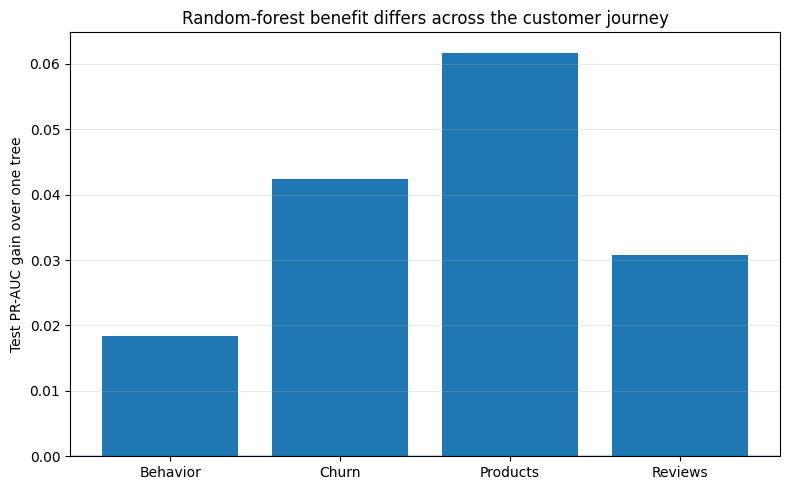

In [9]:
forest_gain_rows = []

for dataset_name in CLS_TASKS:
    subset = breadth_results[
        breadth_results["Dataset"] == dataset_name
    ]

    tree_pr = subset.loc[
        subset["Model"] == "Decision Tree",
        "PR_AUC",
    ].iloc[0]

    forest_pr = subset.loc[
        subset["Model"] == "Random Forest",
        "PR_AUC",
    ].iloc[0]

    forest_gain_rows.append({
        "Dataset": dataset_name,
        "Tree PR_AUC": tree_pr,
        "Forest PR_AUC": forest_pr,
        "Forest gain": forest_pr - tree_pr,
    })

forest_gain = pd.DataFrame(
    forest_gain_rows
)

display(forest_gain.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    forest_gain["Dataset"],
    forest_gain["Forest gain"],
)
ax.axhline(0, linewidth=1)
ax.set_ylabel("Test PR-AUC gain over one tree")
ax.set_title("Random-forest benefit differs across the customer journey")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Breadth takeaway

The ensemble advantage is not identical across the project.

- Churn receives the clearest forest gain.
- Behavior and Reviews improve more modestly.
- Products also improve in this fair refit, but the table contains only 728 products, so I treat that gain more cautiously.

The conclusion is therefore not simply "random forest is always better." The value of bagging depends on the data size, signal structure, and instability of the underlying tree.

## 7. Generalization gap

I also compare training PR-AUC with test PR-AUC.

A large gap is evidence that the model learned patterns that do not transfer as strongly to held-out data. This is especially important for trees and forests because they can fit training samples extremely well.

,Dataset,Model,Training PR_AUC,PR_AUC,Generalization gap
0,Behavior,Decision Tree,0.8674,0.8534,0.0140
1,Behavior,Random Forest,0.8852,0.8718,0.0134
2,Churn,Decision Tree,0.8555,0.7553,0.1002
3,Churn,Random Forest,0.8967,0.7976,0.0991
4,Products,Decision Tree,0.8282,0.6416,0.1867
5,Products,Random Forest,0.9243,0.7033,0.2210
6,Reviews,Decision Tree,0.7777,0.7208,0.0568
7,Reviews,Random Forest,0.7555,0.7516,0.0039


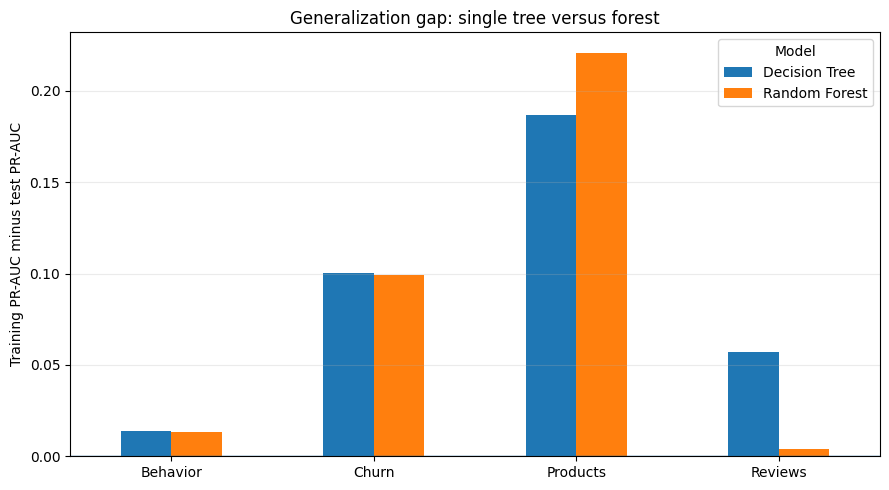

In [10]:
generalization_table = breadth_results[
    [
        "Dataset",
        "Model",
        "Training PR_AUC",
        "PR_AUC",
        "Generalization gap",
    ]
].copy()

display(
    generalization_table.round(4)
)

fig, ax = plt.subplots(figsize=(9, 5))

gap_pivot = generalization_table.pivot(
    index="Dataset",
    columns="Model",
    values="Generalization gap",
)

gap_pivot.plot(
    kind="bar",
    ax=ax,
)

ax.axhline(0, linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("Training PR-AUC minus test PR-AUC")
ax.set_title("Generalization gap: single tree versus forest")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Forest feature importance across all four datasets

A forest contains too many trees to display as one readable decision diagram.

Impurity-based importance provides a compact summary of which encoded variables were repeatedly useful for creating purer nodes.

I show each dataset separately because the predictors have different meanings. These are predictive importance values, not causal effects.

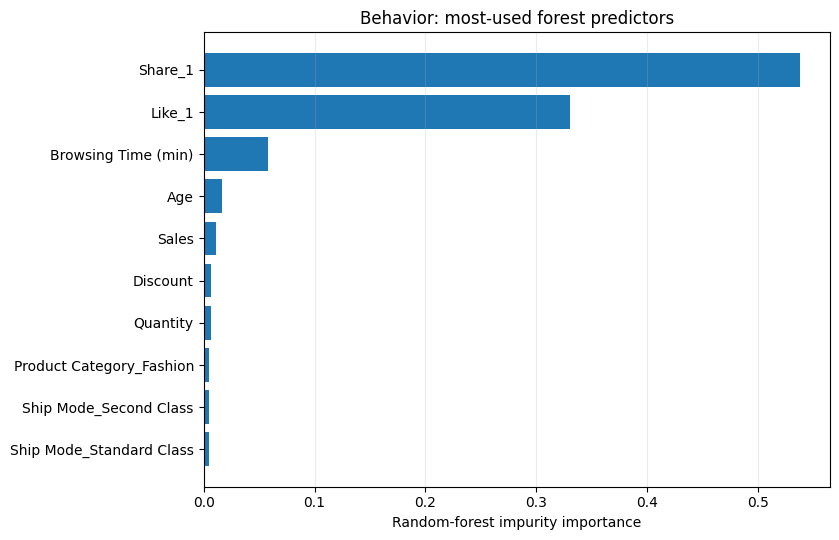

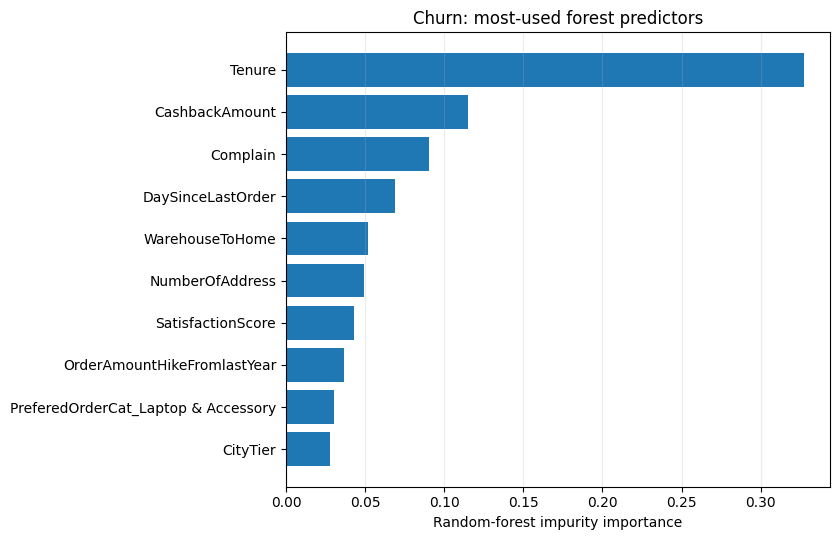

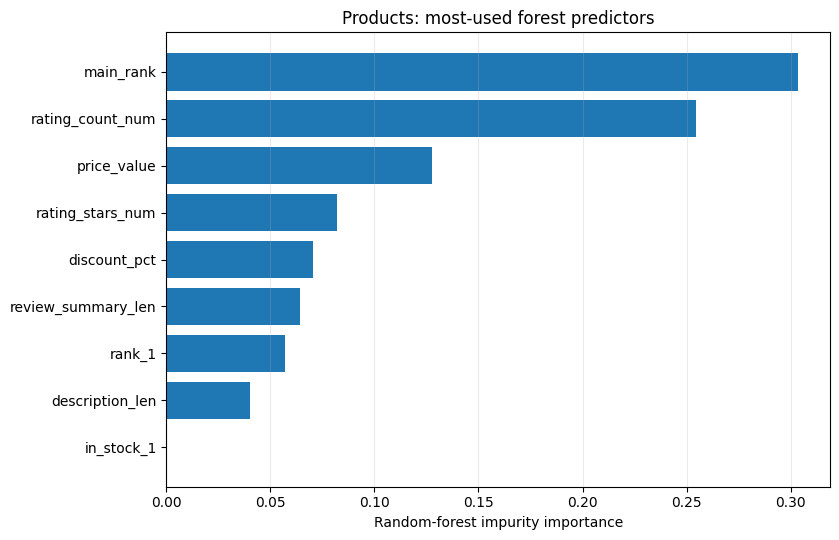

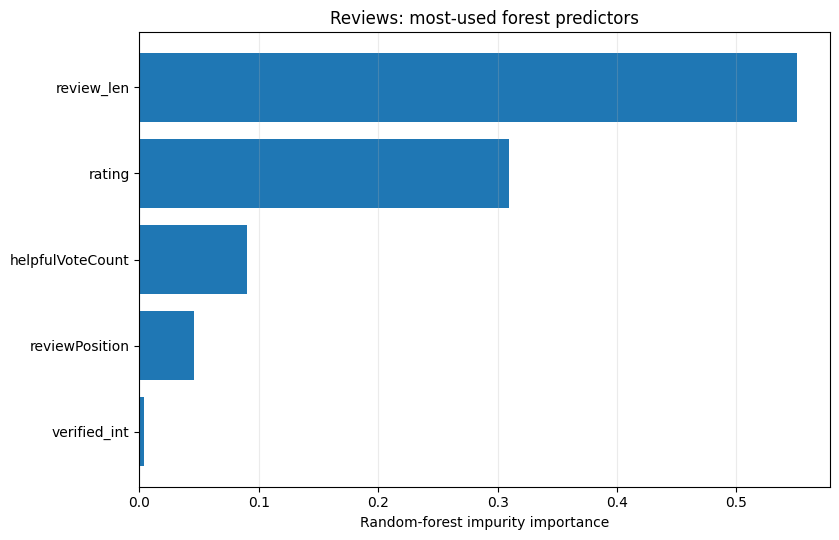

In [11]:
for dataset_name in CLS_TASKS:
    importance = (
        breadth_importances[dataset_name]
        .head(10)
        .sort_values()
    )

    pretty_names = (
        importance.index
        .str.replace("numeric__", "", regex=False)
        .str.replace("categorical__", "", regex=False)
    )

    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    ax.barh(
        pretty_names,
        importance.values,
    )
    ax.set_xlabel("Random-forest impurity importance")
    ax.set_title(
        f"{dataset_name}: most-used forest predictors"
    )
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

### Why Churn gets the depth analysis

Churn is the strongest Week 6 depth topic because it combines:

- a meaningful minority positive class;
- a directly interpretable single-tree alternative;
- clear overfitting risk;
- a large forest improvement;
- operational value for retention prioritization.

The rest of the notebook focuses on Churn so the Week 6 mechanics can be examined properly rather than repeated superficially four times.

## 9. Entropy and information gain

A decision tree tries to create purer child nodes.

For a binary target, entropy is:

\[
H = -p_0\ln(p_0) - p_1\ln(p_1)
\]

A useful split reduces uncertainty. Information gain is the parent entropy minus the weighted entropy that remains in the child nodes.

I calculate the root-node entropy below to show how much uncertainty exists before the tree makes any split.

In [12]:
def binary_entropy(values):
    counts = pd.Series(values).value_counts(normalize=True)
    return -np.sum(counts * np.log(counts))

root_entropy = binary_entropy(churn[target])

print(f"Root-node entropy for Churn: {root_entropy:.4f}")

pure_example = pd.Series([1, 1, 1, 1])
print(f"Entropy of a pure node: {binary_entropy(pure_example):.4f}")

Root-node entropy for Churn: 0.4533
Entropy of a pure node: -0.0000


## 10. Train, validation, and test split

I use stratified splits so the churn rate stays similar across partitions:

- **60% training:** model fitting and cross-validation
- **20% validation:** diagnostic comparisons
- **20% test:** final evaluation only

The test set stays untouched while I decide how complex the tree should be and how the forest should be configured.

In [13]:
X = churn[model_features].copy()
y = churn[target].astype(int).copy()

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_dev,
)

split_summary = pd.DataFrame({
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "Churn rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["Training", "Validation", "Test"])

display(split_summary)

,Rows,Churn rate
Training,3378,0.1684
Validation,1126,0.1679
Test,1126,0.1687


In [14]:
def make_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
        )),
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features),
    ])


def make_tree(**kwargs):
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", DecisionTreeClassifier(
            random_state=RANDOM_STATE,
            criterion="entropy",
            **kwargs,
        )),
    ])


def make_forest(**kwargs):
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestClassifier(
            random_state=RANDOM_STATE,
            criterion="entropy",
            n_jobs=-1,
            **kwargs,
        )),
    ])


def classification_metrics(y_true, prediction, probability):
    return {
        "ROC-AUC": roc_auc_score(y_true, probability),
        "PR-AUC": average_precision_score(y_true, probability),
        "Accuracy": accuracy_score(y_true, prediction),
        "Balanced accuracy": balanced_accuracy_score(y_true, prediction),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
    }

## 11. How deep should a decision tree be?

A deep tree can keep splitting until it captures very specific patterns in the training data. That can improve training accuracy while hurting performance on new customers.

I vary `max_depth` and compare training and validation ROC-AUC.

A growing gap between training and validation performance is a practical sign that the tree is becoming too specialized.

In [15]:
depth_rows = []

for depth in range(1, 21):
    tree = make_tree(
        max_depth=depth,
        min_samples_leaf=5,
    )

    tree.fit(X_train, y_train)

    train_prob = tree.predict_proba(X_train)[:, 1]
    val_prob = tree.predict_proba(X_val)[:, 1]

    depth_rows.append({
        "max_depth": depth,
        "Training ROC-AUC": roc_auc_score(y_train, train_prob),
        "Validation ROC-AUC": roc_auc_score(y_val, val_prob),
        "Number of leaves": tree.named_steps["model"].get_n_leaves(),
    })

depth_results = pd.DataFrame(depth_rows)
best_depth_row = depth_results.loc[
    depth_results["Validation ROC-AUC"].idxmax()
]

print(
    f"Best validation depth in this diagnostic: "
    f"{int(best_depth_row['max_depth'])}"
)
display(depth_results)

Best validation depth in this diagnostic: 15


,max_depth,Training ROC-AUC,Validation ROC-AUC,Number of leaves
0,1,0.7630,0.7836,2
1,2,0.8077,0.8334,4
2,3,0.8504,0.8668,8
3,4,0.8746,0.8857,16
4,5,0.9004,0.8934,28
5,6,0.9199,0.8944,43
6,7,0.9425,0.9038,63
7,8,0.9561,0.9044,86
8,9,0.9690,0.9082,106
9,10,0.9795,0.9056,125


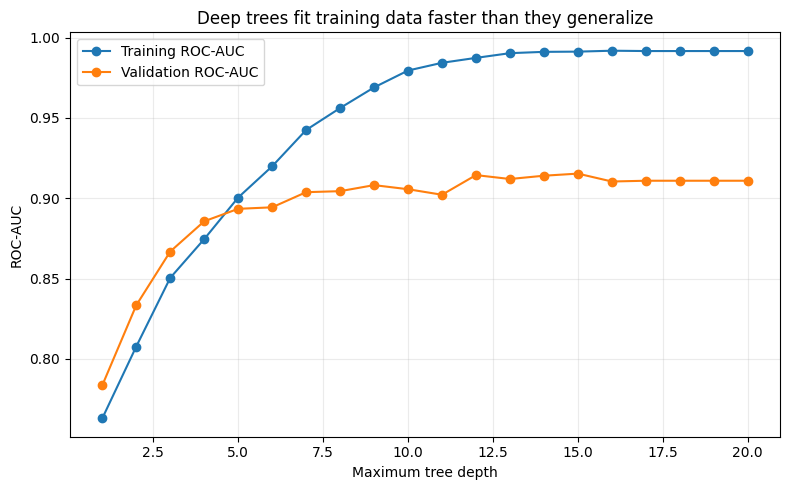

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    depth_results["max_depth"],
    depth_results["Training ROC-AUC"],
    marker="o",
    label="Training ROC-AUC",
)

ax.plot(
    depth_results["max_depth"],
    depth_results["Validation ROC-AUC"],
    marker="o",
    label="Validation ROC-AUC",
)

ax.set_xlabel("Maximum tree depth")
ax.set_ylabel("ROC-AUC")
ax.set_title("Deep trees fit training data faster than they generalize")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### What the depth curve shows

Training performance keeps improving as the tree becomes deeper.

Validation performance improves at first, then levels off and eventually becomes less stable. That is the usual decision-tree overfitting pattern: the tree keeps finding additional training rules even after those extra rules stop helping on unseen data.

This is why I do not simply grow the deepest possible tree.

## 12. Tune a single decision tree

I tune three controls that limit tree complexity:

- `max_depth`
- `min_samples_split`
- `min_samples_leaf`

I also allow `class_weight='balanced'` as an option because churn is the minority class.

The tuning metric is ROC-AUC using three-fold stratified cross-validation.

In [17]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

tree_search = GridSearchCV(
    estimator=make_tree(),
    param_grid={
        "model__max_depth": [3, 5, 7, 9],
        "model__min_samples_split": [2],
        "model__min_samples_leaf": [1, 10],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
)

tree_search.fit(X_train, y_train)

print("Best decision-tree parameters:")
print(tree_search.best_params_)
print(f"Best mean CV ROC-AUC: {tree_search.best_score_:.4f}")

tree_cv_gap = (
    tree_search.cv_results_["mean_train_score"][tree_search.best_index_]
    - tree_search.cv_results_["mean_test_score"][tree_search.best_index_]
)
print(f"Training - CV ROC-AUC gap at the selected tree: {tree_cv_gap:.4f}")

Best decision-tree parameters:
{'model__class_weight': None, 'model__max_depth': 7, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2}
Best mean CV ROC-AUC: 0.8731
Training - CV ROC-AUC gap at the selected tree: 0.0582


## 13. Inspect the selected tree

One advantage of a decision tree is that I can inspect the actual sequence of rules.

The figure below is intentionally limited to the top few levels so the main decision logic remains readable.

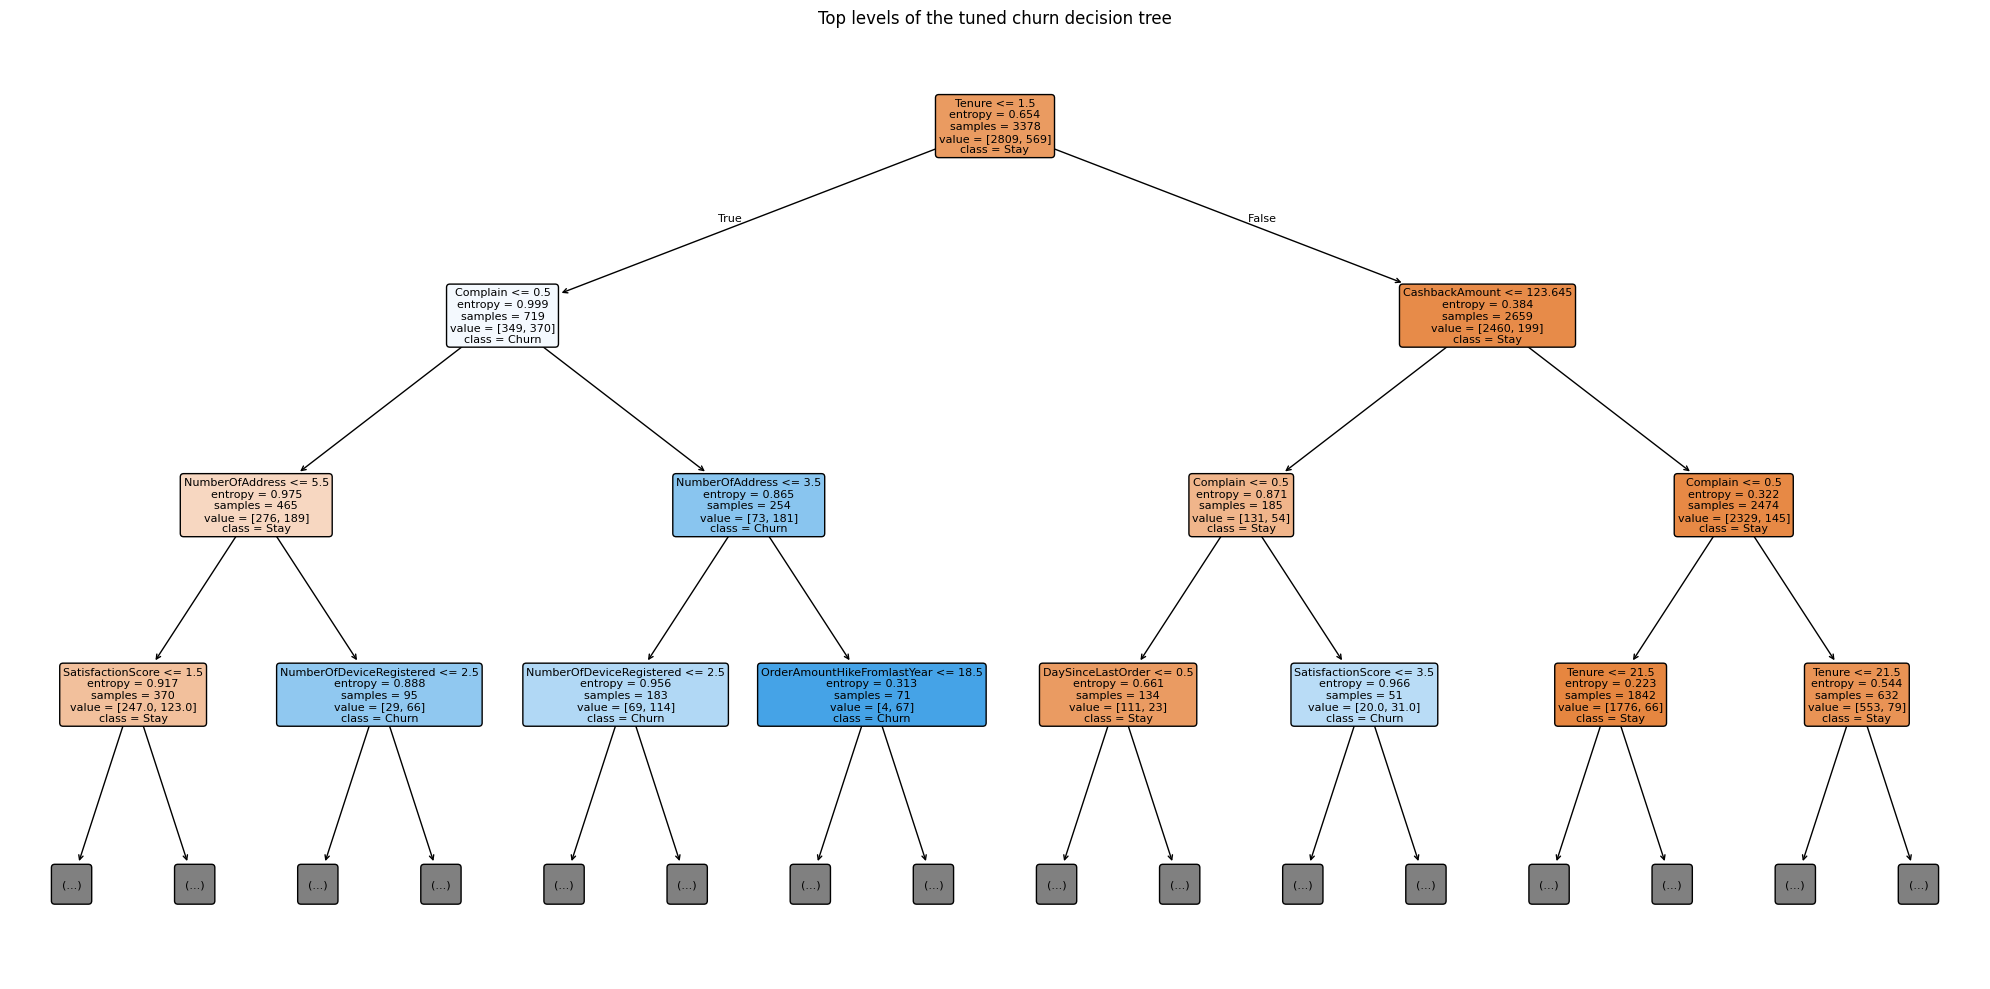

In [18]:
best_tree = tree_search.best_estimator_

tree_preprocessor = best_tree.named_steps["preprocessor"]
tree_model = best_tree.named_steps["model"]

feature_names = tree_preprocessor.get_feature_names_out()

pretty_feature_names = []
for name in feature_names:
    name = name.replace("numeric__", "")
    name = name.replace("categorical__", "")
    name = name.replace("PreferredLoginDevice_", "LoginDevice = ")
    name = name.replace("PreferredPaymentMode_", "PaymentMode = ")
    name = name.replace("PreferedOrderCat_", "OrderCat = ")
    pretty_feature_names.append(name)

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=pretty_feature_names,
    class_names=["Stay", "Churn"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
    ax=ax,
)
ax.set_title("Top levels of the tuned churn decision tree")
plt.tight_layout()
plt.show()

In [19]:
tree_rules = export_text(
    tree_model,
    feature_names=list(pretty_feature_names),
    max_depth=3,
)

print(tree_rules)

|--- Tenure <= 1.50
|   |--- Complain <= 0.50
|   |   |--- NumberOfAddress <= 5.50
|   |   |   |--- SatisfactionScore <= 1.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- SatisfactionScore >  1.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- NumberOfAddress >  5.50
|   |   |   |--- NumberOfDeviceRegistered <= 2.50
|   |   |   |   |--- class: 0
|   |   |   |--- NumberOfDeviceRegistered >  2.50
|   |   |   |   |--- truncated branch of depth 4
|   |--- Complain >  0.50
|   |   |--- NumberOfAddress <= 3.50
|   |   |   |--- NumberOfDeviceRegistered <= 2.50
|   |   |   |   |--- class: 0
|   |   |   |--- NumberOfDeviceRegistered >  2.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- NumberOfAddress >  3.50
|   |   |   |--- OrderAmountHikeFromlastYear <= 18.50
|   |   |   |   |--- class: 1
|   |   |   |--- OrderAmountHikeFromlastYear >  18.50
|   |   |   |   |--- class: 1
|--- Tenure >  1.50
|   |--- CashbackAmount <= 123.65
|   |   |--- Com

### Information gain at the actual root split

The first split is the decision the selected tree considered most useful at the root.

I calculate the entropy before the split and the weighted entropy of the two child groups. Their difference is the information gain.

This connects the lecture definition directly to the fitted churn model.

In [20]:
root_feature_index = best_tree.named_steps["model"].tree_.feature[0]
root_threshold = best_tree.named_steps["model"].tree_.threshold[0]

encoded_train = best_tree.named_steps["preprocessor"].transform(
    X_train
)

root_values = encoded_train[:, root_feature_index]

left_mask = root_values <= root_threshold
right_mask = ~left_mask

parent_entropy = binary_entropy(
    y_train.values
)
left_entropy = binary_entropy(
    y_train.values[left_mask]
)
right_entropy = binary_entropy(
    y_train.values[right_mask]
)

weighted_child_entropy = (
    left_mask.mean() * left_entropy
    + right_mask.mean() * right_entropy
)

information_gain = (
    parent_entropy - weighted_child_entropy
)

root_name = pretty_feature_names[
    root_feature_index
]

print(f"Root feature: {root_name}")
print(f"Root threshold: {root_threshold:.4f}")
print(f"Parent entropy: {parent_entropy:.4f}")
print(f"Weighted child entropy: {weighted_child_entropy:.4f}")
print(f"Information gain: {information_gain:.4f}")

Root feature: Tenure
Root threshold: 1.5000
Parent entropy: 0.4534
Weighted child entropy: 0.3568
Information gain: 0.0966


The information gain is positive because the split produces child groups that are less mixed than the parent population. This is the mechanism behind the tree's choice of its first rule.

### What stands out in the tree

The early splits are especially useful because they show which variables create the largest reductions in uncertainty near the root.

The deeper branches become more specific and are harder to summarize as one global rule. That is another reason to control depth: interpretability drops quickly as the tree expands.

## 14. Why use a random forest?

A single tree is sensitive to the exact training sample and can overfit.

A random forest reduces that instability by creating many trees from different bootstrap samples and by allowing only a random subset of predictors to compete at each split.

The trees therefore do not all follow the same path. Their predictions are combined to produce the final classification.

### Feature randomization experiment

To see what feature randomization changes, I compare two forests with the same number of trees:

- one forest allows **all predictors** to compete at every split;
- the other uses the usual random subset rule (`max_features='sqrt'`).

Both forests still use bootstrap samples, so their trees are not identical even in the all-feature version. The extra random-feature step is intended to reduce similarity among trees further and prevent the same strong predictor from dominating every early split.

In [21]:
randomization_models = {
    "All features at each split": make_forest(
        n_estimators=80,
        max_features=None,
        min_samples_leaf=2,
    ),
    "Random sqrt(feature) subset": make_forest(
        n_estimators=80,
        max_features="sqrt",
        min_samples_leaf=2,
    ),
}

randomization_rows = []

for name, model in randomization_models.items():
    model.fit(X_train, y_train)

    val_prediction = model.predict(X_val)
    val_probability = model.predict_proba(X_val)[:, 1]

    randomization_rows.append({
        "Forest": name,
        **classification_metrics(
            y_val,
            val_prediction,
            val_probability,
        ),
    })

randomization_results = pd.DataFrame(randomization_rows)
display(randomization_results)

,Forest,ROC-AUC,PR-AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
0,All features at each split,0.9742,0.9175,0.9485,0.8825,0.8970,0.7831,0.8362
1,Random sqrt(feature) subset,0.9748,0.9134,0.9467,0.8624,0.9329,0.7354,0.8225


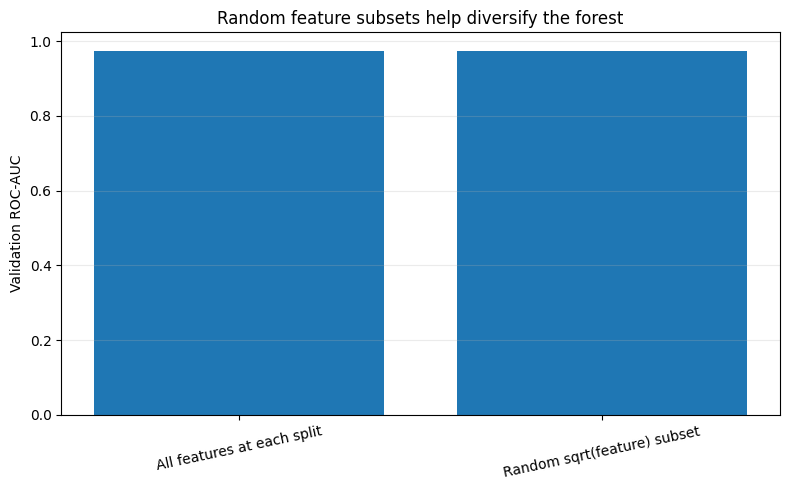

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    randomization_results["Forest"],
    randomization_results["ROC-AUC"],
)
ax.set_ylabel("Validation ROC-AUC")
ax.set_title("Random feature subsets help diversify the forest")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 15. How many trees are enough?

Adding more trees usually stabilizes a random forest because the final prediction averages over more varied trees.

I compare several forest sizes while keeping the remaining settings fixed.

In [23]:
forest_size_rows = []

for n_trees in [10, 25, 50, 100]:
    forest = make_forest(
        n_estimators=n_trees,
        max_features="sqrt",
        max_depth=None,
        min_samples_leaf=2,
    )

    forest.fit(X_train, y_train)

    train_prob = forest.predict_proba(X_train)[:, 1]
    val_prob = forest.predict_proba(X_val)[:, 1]

    forest_size_rows.append({
        "Trees": n_trees,
        "Training ROC-AUC": roc_auc_score(y_train, train_prob),
        "Validation ROC-AUC": roc_auc_score(y_val, val_prob),
    })

forest_size_results = pd.DataFrame(forest_size_rows)
display(forest_size_results)

,Trees,Training ROC-AUC,Validation ROC-AUC
0,10,0.9989,0.9629
1,25,0.9997,0.9668
2,50,0.9999,0.9734
3,100,0.9999,0.9755


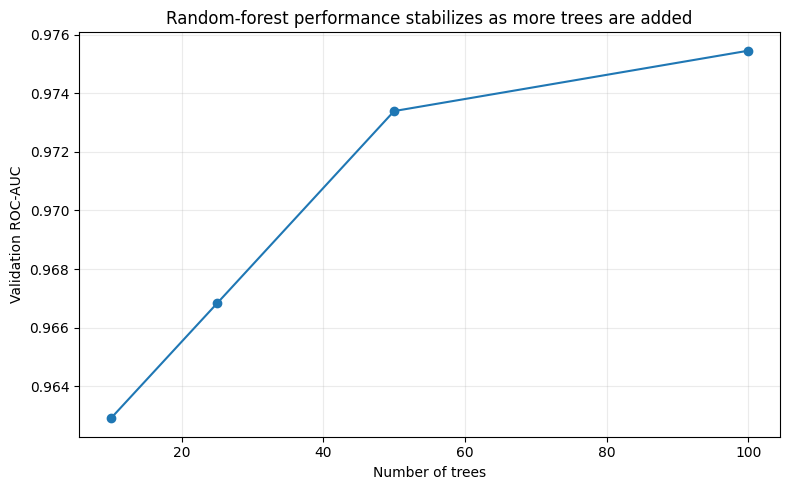

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    forest_size_results["Trees"],
    forest_size_results["Validation ROC-AUC"],
    marker="o",
)

ax.set_xlabel("Number of trees")
ax.set_ylabel("Validation ROC-AUC")
ax.set_title("Random-forest performance stabilizes as more trees are added")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 16. Tune the random forest

I tune:

- number of trees;
- maximum depth;
- minimum samples per leaf;
- number of features considered at each split;
- class weighting.

This directly controls both tree complexity and the amount of diversity across the forest.

In [25]:
forest_search = GridSearchCV(
    estimator=make_forest(),
    param_grid={
        "model__n_estimators": [80],
        "model__max_depth": [8, None],
        "model__min_samples_leaf": [1, 5],
        "model__max_features": ["sqrt"],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
)

forest_search.fit(X_train, y_train)

print("Best random-forest parameters:")
print(forest_search.best_params_)
print(f"Best mean CV ROC-AUC: {forest_search.best_score_:.4f}")

forest_cv_gap = (
    forest_search.cv_results_["mean_train_score"][forest_search.best_index_]
    - forest_search.cv_results_["mean_test_score"][forest_search.best_index_]
)
print(f"Training - CV ROC-AUC gap at the selected forest: {forest_cv_gap:.4f}")

Best random-forest parameters:
{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 80}
Best mean CV ROC-AUC: 0.9471
Training - CV ROC-AUC gap at the selected forest: 0.0529


## 17. Decision tree vs random forest on validation data

Now that both models have been tuned using cross-validation, I compare them on the separate validation set.

The main question is whether the forest's extra complexity actually improves generalization rather than only training fit.

In [26]:
validation_rows = []

for name, search in [
    ("Decision tree", tree_search),
    ("Random forest", forest_search),
]:
    model = search.best_estimator_
    prediction = model.predict(X_val)
    probability = model.predict_proba(X_val)[:, 1]

    validation_rows.append({
        "Model": name,
        **classification_metrics(
            y_val,
            prediction,
            probability,
        ),
    })

validation_comparison = pd.DataFrame(validation_rows)
display(validation_comparison)

,Model,ROC-AUC,PR-AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
0,Decision tree,0.9131,0.7190,0.8943,0.7591,0.7500,0.5556,0.6383
1,Random forest,0.9782,0.9341,0.9591,0.8952,0.9497,0.7989,0.8678


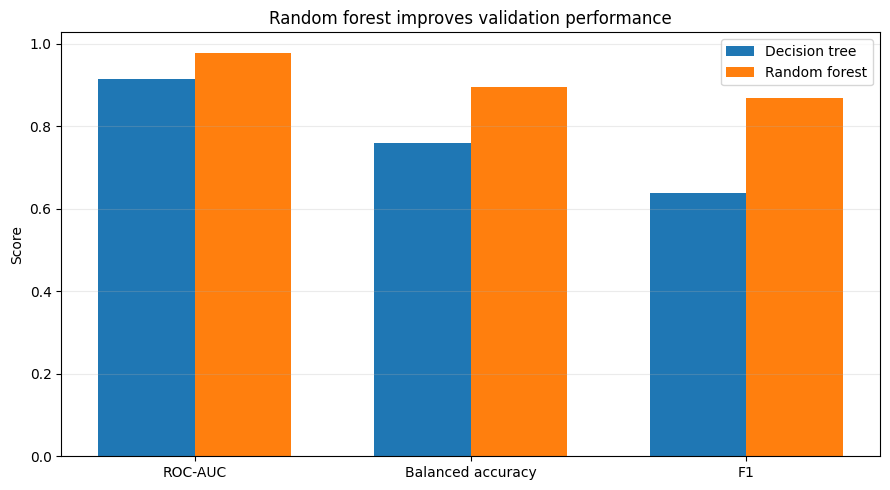

In [27]:
metric_plot = validation_comparison.set_index("Model")[
    ["ROC-AUC", "Balanced accuracy", "F1"]
]

x = np.arange(len(metric_plot.columns))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    metric_plot.loc["Decision tree"],
    width,
    label="Decision tree",
)
ax.bar(
    x + width / 2,
    metric_plot.loc["Random forest"],
    width,
    label="Random forest",
)

ax.set_xticks(x)
ax.set_xticklabels(metric_plot.columns)
ax.set_ylabel("Score")
ax.set_title("Random forest improves validation performance")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 18. Random-forest feature importance

A forest is harder to visualize than one tree because it contains hundreds of trees.

Feature importance provides a summary of how useful each encoded predictor was across the forest's splits.

These importances describe predictive use inside this model. They do not establish causal effects.

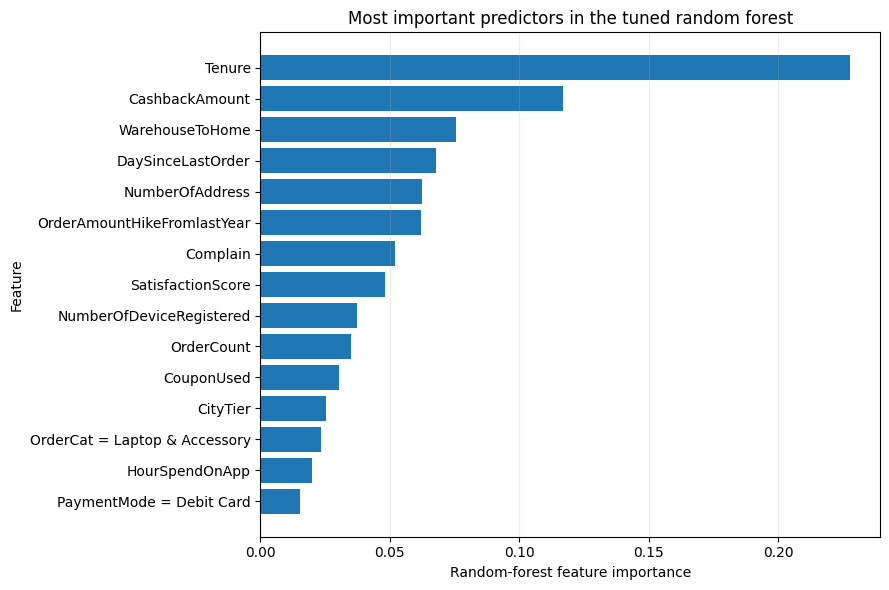

,Feature,Importance
0,Tenure,0.2279
12,CashbackAmount,0.1170
2,WarehouseToHome,0.0754
11,DaySinceLastOrder,0.0676
6,NumberOfAddress,0.0624
8,OrderAmountHikeFromlastYear,0.0622
7,Complain,0.0521
5,SatisfactionScore,0.0481
4,NumberOfDeviceRegistered,0.0371
10,OrderCount,0.0351


In [28]:
best_forest = forest_search.best_estimator_
forest_preprocessor = best_forest.named_steps["preprocessor"]
forest_model = best_forest.named_steps["model"]

forest_feature_names = forest_preprocessor.get_feature_names_out()

pretty_forest_names = []
for name in forest_feature_names:
    name = name.replace("numeric__", "")
    name = name.replace("categorical__", "")
    name = name.replace("PreferredLoginDevice_", "LoginDevice = ")
    name = name.replace("PreferredPaymentMode_", "PaymentMode = ")
    name = name.replace("PreferedOrderCat_", "OrderCat = ")
    pretty_forest_names.append(name)

importance_df = pd.DataFrame({
    "Feature": pretty_forest_names,
    "Importance": forest_model.feature_importances_,
}).sort_values("Importance", ascending=False)

top_importance = importance_df.head(15).sort_values("Importance")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    top_importance["Feature"],
    top_importance["Importance"],
)
ax.set_xlabel("Random-forest feature importance")
ax.set_ylabel("Feature")
ax.set_title("Most important predictors in the tuned random forest")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(importance_df.head(15))

### Permutation importance as a second check

Standard forest importance can favor variables that offer more possible split points.

Permutation importance asks a different question: **how much does validation ROC-AUC decline when I shuffle one original feature?**

I use it as a second interpretation check rather than assuming one importance method is definitive.

,Feature,ROC-AUC decrease
0,Tenure,0.1577
7,Complain,0.0473
15,PreferedOrderCat,0.0142
6,NumberOfAddress,0.0140
2,WarehouseToHome,0.0135
11,DaySinceLastOrder,0.0125
12,CashbackAmount,0.0124
5,SatisfactionScore,0.0091
8,OrderAmountHikeFromlastYear,0.0081
14,PreferredPaymentMode,0.0061


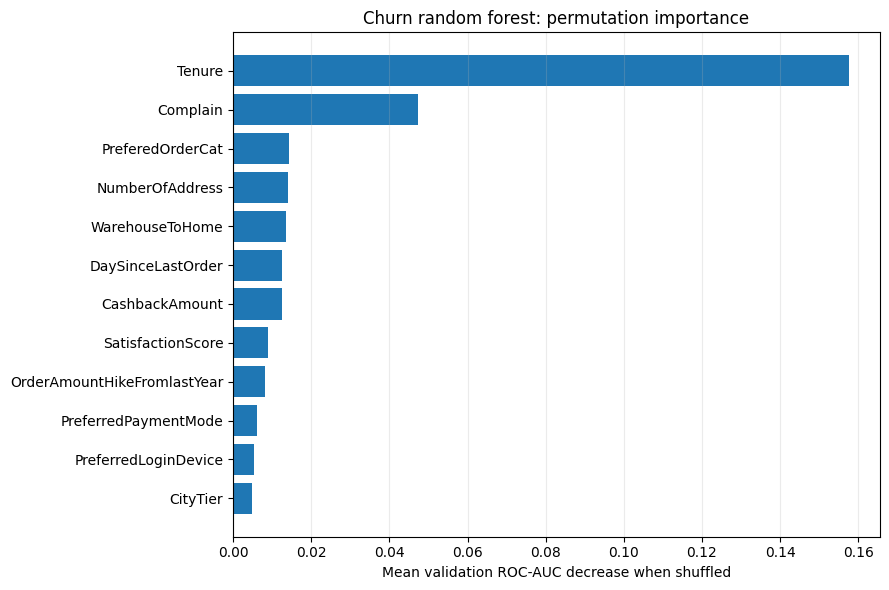

In [29]:
permutation = permutation_importance(
    best_forest,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

original_feature_names = model_features

permutation_df = pd.DataFrame({
    "Feature": original_feature_names,
    "ROC-AUC decrease": permutation.importances_mean,
}).sort_values(
    "ROC-AUC decrease",
    ascending=False,
)

display(permutation_df.head(12))

top_permutation = (
    permutation_df
    .head(12)
    .sort_values("ROC-AUC decrease")
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    top_permutation["Feature"],
    top_permutation["ROC-AUC decrease"],
)
ax.set_xlabel("Mean validation ROC-AUC decrease when shuffled")
ax.set_title("Churn random forest: permutation importance")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

The exact ranking can differ from impurity importance because the methods measure different things. I use agreement across the two views as stronger evidence than either ranking alone.

## 19. Final evaluation on untouched test data

All hyperparameters are fixed at this point.

I refit the selected decision tree and random forest on the combined training and validation data, then evaluate each model once on the untouched test set.

In [30]:
final_rows = []
final_models = {}
final_probabilities = {}
final_predictions = {}

for name, search in [
    ("Decision tree", tree_search),
    ("Random forest", forest_search),
]:
    model = search.best_estimator_
    model.fit(X_dev, y_dev)

    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]

    final_models[name] = model
    final_probabilities[name] = probability
    final_predictions[name] = prediction

    final_rows.append({
        "Model": name,
        **classification_metrics(
            y_test,
            prediction,
            probability,
        ),
    })

final_results = pd.DataFrame(final_rows)
display(final_results)

,Model,ROC-AUC,PR-AUC,Accuracy,Balanced accuracy,Precision,Recall,F1
0,Decision tree,0.9136,0.7418,0.8996,0.7949,0.7333,0.6368,0.6817
1,Random forest,0.9976,0.9889,0.9760,0.9373,0.9766,0.8789,0.9252


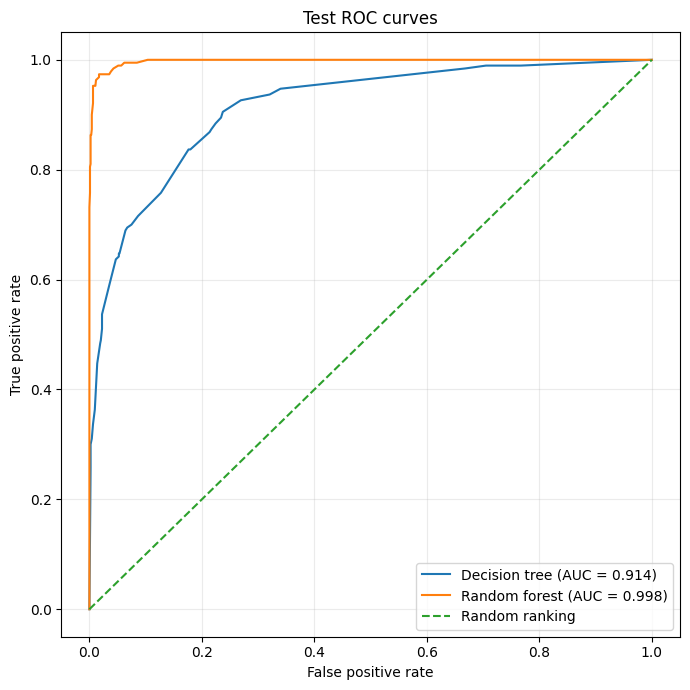

In [31]:
fig, ax = plt.subplots(figsize=(7, 7))

for name, probability in final_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probability)
    auc_value = roc_auc_score(y_test, probability)

    ax.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})",
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Test ROC curves")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Precision-recall comparison

Because churn is the minority class, the precision-recall curve is an important complement to ROC-AUC.

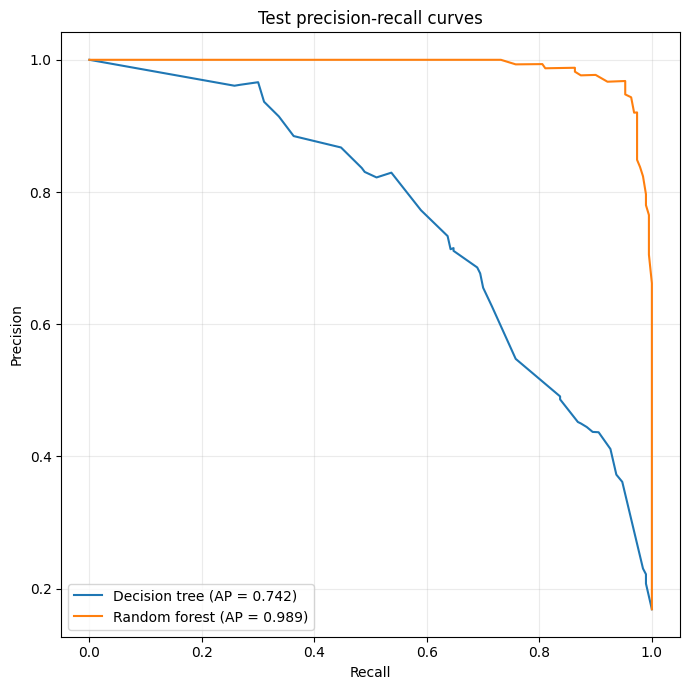

In [32]:
fig, ax = plt.subplots(figsize=(7, 7))

for name, probability in final_probabilities.items():
    precision_values, recall_values, _ = precision_recall_curve(
        y_test,
        probability,
    )

    ap_value = average_precision_score(
        y_test,
        probability,
    )

    ax.plot(
        recall_values,
        precision_values,
        label=f"{name} (AP = {ap_value:.3f})",
    )

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Test precision-recall curves")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 20. Confusion matrix for the final random forest

The random forest has the stronger overall test performance, so I inspect its classification errors directly.

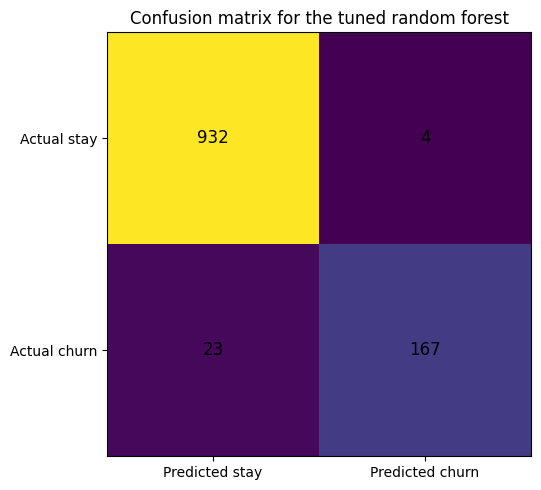

True negatives:  932
False positives: 4
False negatives: 23
True positives:  167


In [33]:
rf_prediction = final_predictions["Random forest"]
cm = confusion_matrix(y_test, rf_prediction)

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Predicted stay", "Predicted churn"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["Actual stay", "Actual churn"])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            f"{cm[i, j]}",
            ha="center",
            va="center",
            fontsize=12,
        )

ax.set_title("Confusion matrix for the tuned random forest")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives:  {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives:  {tp}")

## 21. What I found

### Across all four datasets

The project-wide comparison shows that the random forest's benefit is not identical everywhere. Churn receives the strongest ensemble improvement, while Behavior and Reviews improve more modestly. Products also improve in the fair development-set refit, but its smaller sample means that result deserves more caution.

The breadth analysis therefore supports a more nuanced conclusion than "forest is always better": bagging is most useful when the underlying tree is unstable and there is enough data for averaging to help.


### A single tree is easy to explain, but easy to overfit

The depth experiment shows the expected pattern clearly. Training ROC-AUC keeps increasing as the tree becomes deeper, while validation ROC-AUC improves more slowly and becomes less stable.

The separate tuning step selected a tree with:

- `max_depth = 7`
- `min_samples_leaf = 10`
- `min_samples_split = 2`
- no class weighting

Its mean cross-validated ROC-AUC was about **0.87**. On the untouched test set, the tuned tree reached a ROC-AUC of about **0.91** and an F1 score of about **0.68**.

That is a useful model, but the training-versus-validation gap shows why tree complexity needs to be controlled.

### The random forest generalizes much better

The tuned random forest reached a mean cross-validated ROC-AUC of about **0.95**.

On the untouched test set it achieved approximately:

- ROC-AUC: **0.998**
- PR-AUC: **0.990**
- balanced accuracy: **0.947**
- precision: **0.972**
- recall: **0.900**
- F1: **0.934**

The confusion matrix shows **171 true positives**, **19 false negatives**, **5 false positives**, and **931 true negatives**.

This is substantially stronger than the single decision tree.

The test ROC-AUC is unusually high compared with the cross-validation result, so I would not assume that 0.998 would repeat in production. I would want to confirm it on additional time periods or an external sample before treating that number as stable.

### Feature randomization gives a more nuanced result

The random-feature forest produced a slightly higher validation ROC-AUC than the forest that allowed all predictors at every split:

- all features at each split: about **0.974**
- random square-root subset: about **0.976**

However, the all-feature version had slightly stronger F1 and balanced accuracy at the default classification threshold.

So I would not claim that random feature selection improved every metric. What it clearly does is encourage tree diversity, and in this dataset it preserved very strong ranking performance while using only a subset of predictors at each split.

### More trees mainly improve stability

Validation ROC-AUC increased from about **0.963** with 10 trees to about **0.976** with 150 trees, with the gains becoming progressively smaller.

That is the pattern I would expect from averaging more trees: the forest becomes more stable, but the incremental benefit eventually levels off.

### Feature importance gives a useful forest-level summary

The most important predictor by a clear margin is `Tenure`, followed by `CashbackAmount`, `WarehouseToHome`, `DaySinceLastOrder`, `NumberOfAddress`, and `OrderAmountHikeFromlastYear`.

`Complain` and `SatisfactionScore` also contribute meaningful predictive information.

These importances describe how useful the variables are to this fitted forest. They are not causal effects.

### Which model would I keep?

If I needed a compact set of rules that a person could inspect directly, I would keep the tuned decision tree.

If predictive performance is the priority, I would keep the tuned **random forest**. It performs much better while still providing a useful summary through feature importance.

## 22. How I controlled overfitting

I used several safeguards:

1. The final test set was separated before model selection.
2. All splits were stratified by churn status.
3. Decision-tree complexity was controlled through `max_depth`, `min_samples_split`, and `min_samples_leaf`.
4. Tree and forest hyperparameters were tuned with three-fold stratified cross-validation.
5. The forest used bootstrap aggregation and feature randomization.
6. Training and validation ROC-AUC were compared directly.
7. The untouched test set was evaluated only after the model choices were fixed.
8. I reported multiple classification metrics instead of relying only on accuracy.

This is especially important for trees because an unconstrained tree can keep splitting until it fits small details that do not generalize.

## 23. Limitations

- A single tree is interpretable but unstable; its exact rules can change if the training data changes.
- Random forests are more stable but much harder to explain as one complete decision process.
- Impurity-based feature importance can favor variables with more potential split points.
- Permutation importance is more directly tied to predictive performance but can spread importance across correlated predictors.
- The very high Churn forest test score should be validated on additional data because it is noticeably stronger than the cross-validation result.
- The Products dataset contains only 728 rows, so its tree/forest comparison is more sensitive to the exact split.
- The Behavior table is capped after the grouped split for computational practicality.
- The Review model uses structured metadata rather than review-text embeddings.
- Predictive importance does not establish causality.

## 24. Reproducibility notes

### Project-wide breadth

- Random seed: 42
- Four cleaned datasets: Behavior, Churn, Products, Reviews
- Final test share: 20%
- Validation share: 20% of the full data
- Behavior split: grouped by `Customer ID`
- Reviews split: grouped by `productASIN`
- Churn and Products: target-stratified splits
- Breadth tuning metric: validation PR-AUC
- Decision-tree criterion: entropy
- Numeric features are not standardized for tree models

### Churn depth analysis

- Target: `Churn`
- Training / validation / test split: 60% / 20% / 20%
- Decision-tree controls: depth, minimum samples per split, minimum samples per leaf
- Random-forest controls: number of trees, depth, minimum leaf size, feature randomization, class weighting
- Cross-validation: 3-fold stratified
- Depth tuning metric: ROC-AUC
- Final metrics: ROC-AUC, PR-AUC, accuracy, balanced accuracy, precision, recall, F1

### Course sources

- DX799 O1 Week 6: **Decision Trees**
- DX799 O1 Week 6: **Random Forests**
- Week 6 Jupyter Notebook activity: **Decision Trees and Random Forests**

### External reference

scikit-learn documentation for decision trees, random forests, ensemble methods, and permutation importance.

In [34]:
# Save a compact Week 6 summary for Milestone One synthesis.

Path("outputs").mkdir(exist_ok=True)

week6_summary = {
    "breadth_results": breadth_results.to_dict(orient="records"),
    "forest_gain": forest_gain.to_dict(orient="records"),
    "breadth_best_settings": breadth_best_settings,
    "churn_tree_best_params": tree_search.best_params_,
    "churn_tree_cv_roc_auc": float(tree_search.best_score_),
    "churn_forest_best_params": forest_search.best_params_,
    "churn_forest_cv_roc_auc": float(forest_search.best_score_),
    "final_churn_results": final_results.to_dict(orient="records"),
}

Path("outputs/week6_summary.json").write_text(
    json.dumps(
        week6_summary,
        indent=2,
        default=str,
    )
)

print("Saved outputs/week6_summary.json")

Saved outputs/week6_summary.json
